# Aula 2 — Tratamento de faltantes, duplicatas e outliers  
**Versão do aluno — preenchimento guiado**

## Objetivos
- Identificar problemas de qualidade na base de dados.
- Tratar valores faltantes.
- Remover duplicatas.
- Identificar e tratar outliers.
- Comparar a base antes e depois do tratamento.


## Instruções
Preencha as células indicadas durante a condução do professor.  
Sempre registre suas observações técnicas sobre o que foi encontrado na base.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)


## 1. Carregamento da base

In [4]:
# Carregue o arquivo CSV da aula
df = pd.read_csv('dados_aula1_machine_learning_industria.csv')

# Exiba as 5 primeiras linhas
df.head()

,timestamp,lote_producao,operador,modo_controle,status_valvula,setpoint_vazao_l_min,vazao_medida_l_min,pressao_linha_bar,temperatura_processo_c,abertura_valvula_pct,vibracao_bomba_mm_s,tempo_resposta_ms,ph_produto,densidade_produto_g_cm3,status_instrumentacao
0,2026-01-10 08:00:00,Lote_A,op_b,automatico,normal,121.44,128.08,3.518,95.00,56.97,2.960,220.8,7.09,1.069,estavel
1,2026-01-10 09:00:00,Lote_D,op_c,cascata,normal,126.17,119.32,4.616,43.34,63.26,2.532,402.1,6.99,1.053,inspecao
2,2026-01-10 10:00:00,Lote_B,op_d,manual,intermitente,128.54,129.11,4.118,40.67,63.14,2.182,284.1,6.72,1.021,inspecao
3,2026-01-10 11:00:00,Lote_C,op_a,automatico,intermitente,106.50,102.68,3.547,43.94,64.75,2.772,486.3,6.67,1.093,inspecao
4,2026-01-10 12:00:00,Lote_C,op_a,automatico,normal,101.59,NaN,4.085,102.00,83.82,3.173,283.3,6.66,1.004,estavel


## 2. Diagnóstico inicial

### Atividade
1. Verifique as dimensões da base.  
2. Liste os tipos de dados.  
3. Conte os valores faltantes por coluna.  
4. Conte quantas linhas duplicadas existem.


In [5]:
# COMPLETE
print('Dimensões da base:', df.shape)

print('\nTipos de dados:')
print(df.info())

print('\nValores faltantes por coluna:')
print(df.isnull().sum())

print('\nQuantidade de linhas duplicadas:')
print(df.duplicated().sum())

Dimensões da base: (188, 15)

Tipos de dados:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188 entries, 0 to 187
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   timestamp                188 non-null    object 
 1   lote_producao            188 non-null    object 
 2   operador                 183 non-null    object 
 3   modo_controle            183 non-null    object 
 4   status_valvula           188 non-null    object 
 5   setpoint_vazao_l_min     188 non-null    float64
 6   vazao_medida_l_min       176 non-null    float64
 7   pressao_linha_bar        178 non-null    float64
 8   temperatura_processo_c   178 non-null    float64
 9   abertura_valvula_pct     188 non-null    float64
 10  vibracao_bomba_mm_s      188 non-null    float64
 11  tempo_resposta_ms        177 non-null    float64
 12  ph_produto               180 non-null    float64
 13  densidade_produto_g_cm3  188 non-n

**Registro do aluno:**  
Quais foram os principais problemas encontrados na base?

O dataset apresenta informações faltando e linhas duplicadas.

## 3. Separação entre colunas numéricas e categóricas

In [6]:
df.select_dtypes(exclude = np.number).columns

Index(['timestamp', 'lote_producao', 'operador', 'modo_controle',
       'status_valvula', 'status_instrumentacao'],
      dtype='object')

In [7]:
# COMPLETE
colunas_numericas = ['setpoint_vazao_l_min', 'vazao_medida_l_min', 'pressao_linha_bar', 'temperatura_processo_c', 'abertura_valvula_pct', 'vibracao_bomba_mm_s', 'tempo_resposta_ms', 'ph_produto', 'densidade_produto_g_cm3']
colunas_categoricas = ['timestamp', 'lote_producao', 'operador', 'modo_controle', 'status_valvula', 'status_instrumentacao']

print('Colunas numéricas:', colunas_numericas)
print('\nColunas categóricas:', colunas_categoricas)

Colunas numéricas: ['setpoint_vazao_l_min', 'vazao_medida_l_min', 'pressao_linha_bar', 'temperatura_processo_c', 'abertura_valvula_pct', 'vibracao_bomba_mm_s', 'tempo_resposta_ms', 'ph_produto', 'densidade_produto_g_cm3']

Colunas categóricas: ['timestamp', 'lote_producao', 'operador', 'modo_controle', 'status_valvula', 'status_instrumentacao']


## 4. Tratamento de valores faltantes

### Estratégia proposta
- numéricas: preencher com a mediana;
- categóricas: preencher com a moda.


In [8]:
df_tratado = df.copy()

# COMPLETE o tratamento das colunas numéricas
for col in colunas_numericas:
    if df_tratado[col].isna().sum() > 0:
        mediana = df_tratado[col].median()
        df_tratado[col] = df_tratado[col].fillna(mediana)

# COMPLETE o tratamento das colunas categóricas
for col in colunas_categoricas:
    if df_tratado[col].isna().sum() > 0:
        moda = df_tratado[col].mode()
        df_tratado[col] = df_tratado[col].fillna(moda[0])

print(df_tratado.isna().sum())

timestamp                  0
lote_producao              0
operador                   0
modo_controle              0
status_valvula             0
setpoint_vazao_l_min       0
vazao_medida_l_min         0
pressao_linha_bar          0
temperatura_processo_c     0
abertura_valvula_pct       0
vibracao_bomba_mm_s        0
tempo_resposta_ms          0
ph_produto                 0
densidade_produto_g_cm3    0
status_instrumentacao      0
dtype: int64


In [9]:
df_tratado.head()

,timestamp,lote_producao,operador,modo_controle,status_valvula,setpoint_vazao_l_min,vazao_medida_l_min,pressao_linha_bar,temperatura_processo_c,abertura_valvula_pct,vibracao_bomba_mm_s,tempo_resposta_ms,ph_produto,densidade_produto_g_cm3,status_instrumentacao
0,2026-01-10 08:00:00,Lote_A,op_b,automatico,normal,121.44,128.080,3.518,95.00,56.97,2.960,220.8,7.09,1.069,estavel
1,2026-01-10 09:00:00,Lote_D,op_c,cascata,normal,126.17,119.320,4.616,43.34,63.26,2.532,402.1,6.99,1.053,inspecao
2,2026-01-10 10:00:00,Lote_B,op_d,manual,intermitente,128.54,129.110,4.118,40.67,63.14,2.182,284.1,6.72,1.021,inspecao
3,2026-01-10 11:00:00,Lote_C,op_a,automatico,intermitente,106.50,102.680,3.547,43.94,64.75,2.772,486.3,6.67,1.093,inspecao
4,2026-01-10 12:00:00,Lote_C,op_a,automatico,normal,101.59,118.565,4.085,102.00,83.82,3.173,283.3,6.66,1.004,estavel


**Registro do aluno:**  
Por que a mediana pode ser mais interessante do que a média em bases com valores extremos?


Porque ao calcular a média são usados todos os valores de uma base de dados, acontece que esses valores podem não condizer com a realidade. Os valores extremos tendem a deixar a média de uma situação muito fora do que é de verdade, portanto, é interessante usar os valores que estão na mediana por serem os mais próximos da realidade.

## 5. Remoção de duplicatas

In [10]:
# COMPLETE
linhas_antes = len(df)
duplicatas_antes = df.duplicated().sum()

df_tratado = df_tratado.drop_duplicates()

linhas_depois = len(df_tratado)
duplicatas_depois = df_tratado.duplicated().sum()

print('Linhas antes:', linhas_antes)
print('Duplicatas antes:', duplicatas_antes)
print('Linhas depois:', linhas_depois)
print('Duplicatas depois:', duplicatas_depois)

Linhas antes: 188
Duplicatas antes: 8
Linhas depois: 180
Duplicatas depois: 0


## 6. Identificação de outliers com IQR

Use as variáveis abaixo:
- `vazao_medida_l_min`
- `pressao_linha_bar`
- `temperatura_processo_c`
- `tempo_resposta_ms`
- `vibracao_bomba_mm_s`


In [11]:
variaveis_outliers = [
    'vazao_medida_l_min',
    'pressao_linha_bar',
    'temperatura_processo_c',
    'tempo_resposta_ms',
    'vibracao_bomba_mm_s'
]

outliers_resumo = []

for col in variaveis_outliers:
    # COMPLETE os cálculos
    q1 = df_tratado[col].quantile(0.25)
    q3 = df_tratado[col].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    qtd_outliers = ((df_tratado[col] < limite_inferior) | (df_tratado[col] > limite_superior)).sum()

    outliers_resumo.append({
        'coluna': col,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'limite_inferior': limite_inferior,
        'limite_superior': limite_superior,
        'qtd_outliers': int(qtd_outliers)
    })

pd.DataFrame(outliers_resumo)

,coluna,Q1,Q3,IQR,limite_inferior,limite_superior,qtd_outliers
0,vazao_medida_l_min,110.5775,128.630,18.0525,83.49875,155.70875,3
1,pressao_linha_bar,3.5670,4.107,0.5400,2.75700,4.91700,4
2,temperatura_processo_c,40.0625,46.260,6.1975,30.76625,55.55625,6
3,tempo_resposta_ms,283.9000,372.550,88.6500,150.92500,505.52500,4
4,vibracao_bomba_mm_s,1.7760,2.708,0.9320,0.37800,4.10600,2


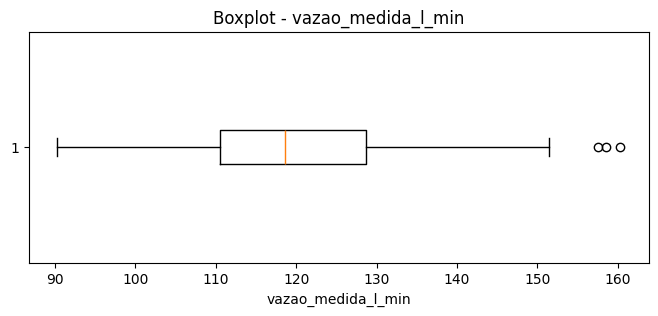

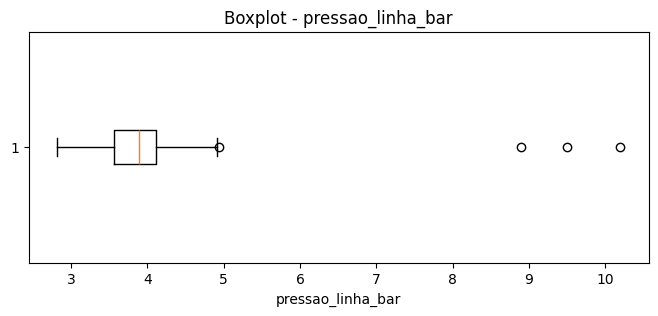

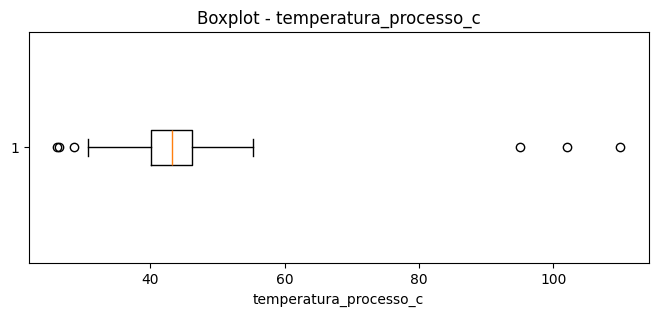

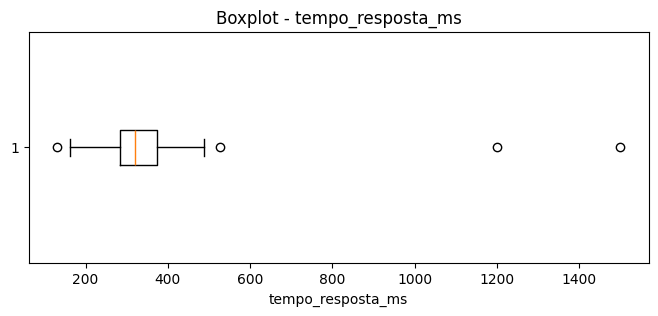

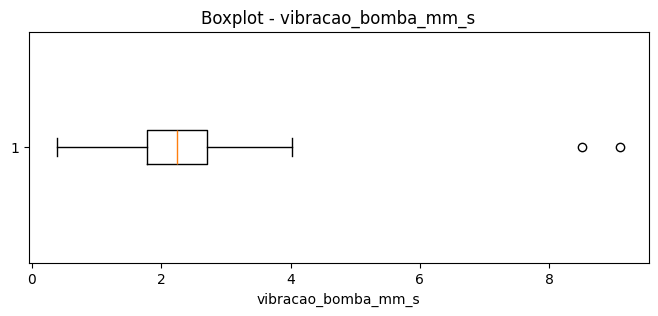

In [12]:
# Gere boxplots das variáveis escolhidas
for col in variaveis_outliers:
    plt.figure(figsize=(8, 3))
    # COMPLETE
    plt.boxplot(df_tratado[col].dropna(), vert = False)
    plt.title(f'Boxplot - {col}')
    plt.xlabel(col)
    plt.show()

## 7. Tratamento de outliers por capping

In [13]:
df_limpo = df_tratado.copy()

for col in variaveis_outliers:
    # COMPLETE
    q1 = df_limpo[col].quantile(0.25)
    q3 = df_limpo[col].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    df_limpo[col] = df_limpo[col].clip(lower = limite_inferior, upper = limite_superior)

print('Tratamento de outliers finalizado.')

Tratamento de outliers finalizado.


## 8. Comparação antes e depois

In [14]:
df.duplicated().sum()

np.int64(8)

In [15]:
# COMPLETE
resumo_comparacao = pd.DataFrame({
    'base_original': [188, 61, 8],
    'base_tratada': [180, 0, 0]
}, index=['quantidade_linhas', 'total_faltantes', 'total_duplicatas'])

resumo_comparacao

,base_original,base_tratada
quantidade_linhas,188,180
total_faltantes,61,0
total_duplicatas,8,0


**Registro do aluno:**  
Quais melhorias a base apresentou após o tratamento?


A base de dados agora está totalmente preenchida e não possui mais linhas duplicadas. Com a base de dados totalmente preenchida, é possível treinar um modelo mais preciso.

## 9. Exportação da base tratada

In [16]:
# COMPLETE
df_tratado.to_csv("dados_tratados.csv", index = False)
print('Arquivo salvo com sucesso.')

Arquivo salvo com sucesso.


## 10. Reflexão final
1. Quais decisões de limpeza exigiriam validação com especialista de processo?
- `vibracao_bomba_mm_s`, pois pode ser algo comum da bomba.
2. Em um ambiente industrial real, todo outlier deve ser removido? Justifique.
- Depende, porque se o outlier for um erro de medição, é válido corrigir ou remover. Caso o outlier for um evento extremo ou algo comum de acontecer no ambiente industrial, é válido manter.
3. Como uma base mal tratada pode prejudicar um modelo preditivo?
- Se a base de dados não tiver o tratamento adequado, os cálculos necessários para fazer uma previsão estarão incorretos. Por exemplo, ao treinar um modelo com um dataset não tratado, os registros duplicados acabariam tendo mais volume do que o ideal, distorcendo toda a realidade do que realmente ocorre no ambiente de trabalho.